# LAB 2 for CS4243: Perspective-Aware Virtual Advertisement Overlay
## Notebook 1 — Keypoints, descriptors, matching, and planar geometry
> **Introduction.** This notebook is part of **LAB 2 for CS4243**. It develops visual intuition for the two
> branches of Stage 1 (Localise) you implement in `overlaylab/keypoints.py` and `overlaylab/geometry.py`, using a
> deterministic subset of the common clip (every eighth frame at 640 px) and synthetic sequences with known
> answers. The parameter sweeps, the DLT conditioning study and the RANSAC iteration study are *explorations* for your
> own understanding (cells marked **EXPLORATION**): they are not report questions.
> Cells marked **ABLATION / SANITY-CHECK / COMPARISON** are the only places where `cv2.SIFT`,
> `cv2.findHomography` and `cv2.warpPerspective` may appear.

## Learning goals
See how the window scale, the sensitivity constant and the NMS mode change *where* corners land; watch the ratio test
reject repetitive structure; separate in-plane rotation (absorbed by the descriptor) from scale and viewpoint change
(not absorbed); inspect the singular values of the DLT system with and without normalisation; and relate RANSAC's
iteration count to the inlier fraction.

## 1. Imports and reproducible configuration
`notebook_config()` fixes the settings used throughout Notebooks 1–3. The reference board is resized by the same factor
as the frames so that the board appears at a comparable scale in both images.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import cv2

from overlaylab import data, metrics, visualize as viz
from overlaylab import supplied as sp
from overlaylab.config import notebook_config, replace
from overlaylab.keypoints import harris_response, detect_corners, describe_keypoints, match_descriptors
from overlaylab.geometry import normalise_points, dlt_homography, ransac_homography, transfer_points, warp_artwork
from overlaylab import synthetic as syn

config = notebook_config()
indices, frames, factor = data.load_notebook_subset()
reference_full = data.load_reference()
reference = sp.resize_width(reference_full, int(round(reference_full.shape[1] * factor)))
config.localisation.warp.reference_shape = reference.shape[:2]
artwork = data.load_artwork("ad")
gt_val = data.subset_gt_corners(indices, factor, "validation")
gt_test = data.subset_gt_corners(indices, factor, "test")
print(f"{len(frames)} subset frames of {frames[0].shape[1]}x{frames[0].shape[0]} (scale {factor:.3f}); "
      f"reference {reference.shape[1]}x{reference.shape[0]}; {len(gt_val)} validation / {len(gt_test)} test annotated frames")

63 subset frames of 640x360 (scale 0.500); reference 198x165; 13 validation / 13 test annotated frames


## 2. The clip, the reference, and the artwork
Ground-truth corners exist on every 16th frame of the full clip on which the whole poster is visible (26 frames); here
they are drawn on the subset frames that carry them. Validation frames (even annotation index) are the only frames you
may use to choose thresholds. The clip is real hand-held footage (POT-280 "Coke"), so the corners carry annotation
noise of about a pixel; keep that floor in mind when you read corner errors.

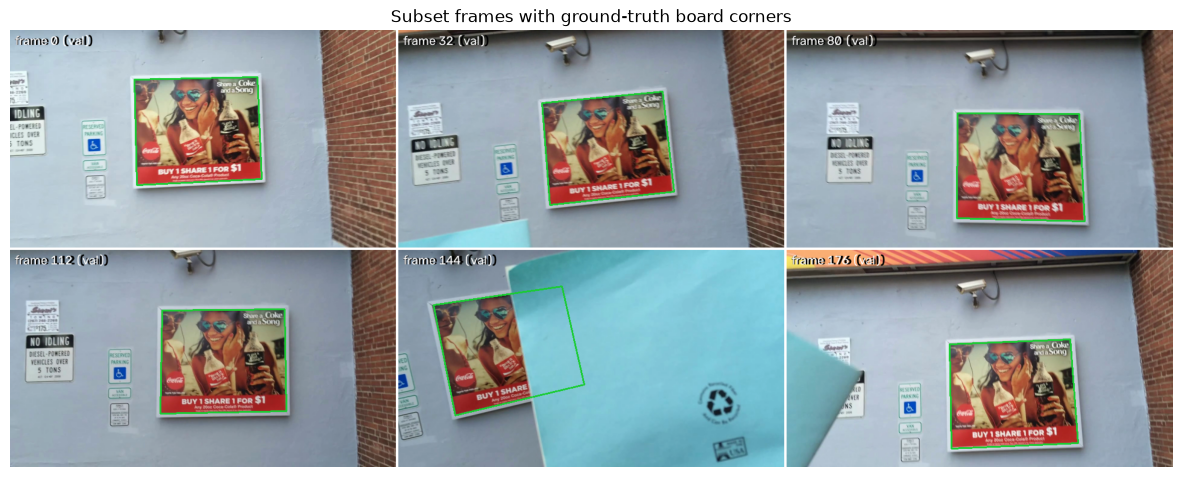

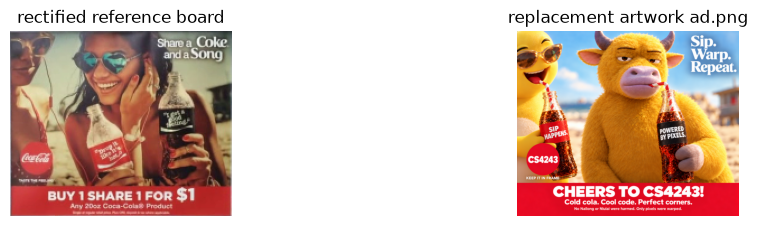

In [2]:
show = [i for i in indices if i in gt_val][:6]
panels = [viz.label(viz.draw_quad(frames[indices.index(i)], (gt_val | gt_test)[i]), f"frame {i} ({'val' if i in gt_val else 'test'})") for i in show]
plt.figure(figsize=(15, 6)); plt.imshow(viz.montage(panels, cols=3)); plt.axis("off"); plt.title("Subset frames with ground-truth board corners")
fig, axes = plt.subplots(1, 2, figsize=(12, 2.4))
axes[0].imshow(reference); axes[0].set_title("rectified reference board"); axes[0].axis("off")
axes[1].imshow(artwork); axes[1].set_title("replacement artwork ad.png"); axes[1].axis("off")
plt.show()

## 3. Harris corners and the two NMS modes
The response map should peak at corners of the poster texture and stay non-positive on edges and flat
regions. Compare how `"window"` and `"radius"` distribute corners, and how many fall on the board versus the background
(use the ground-truth quadrilateral only to *count*, never to initialise anything).

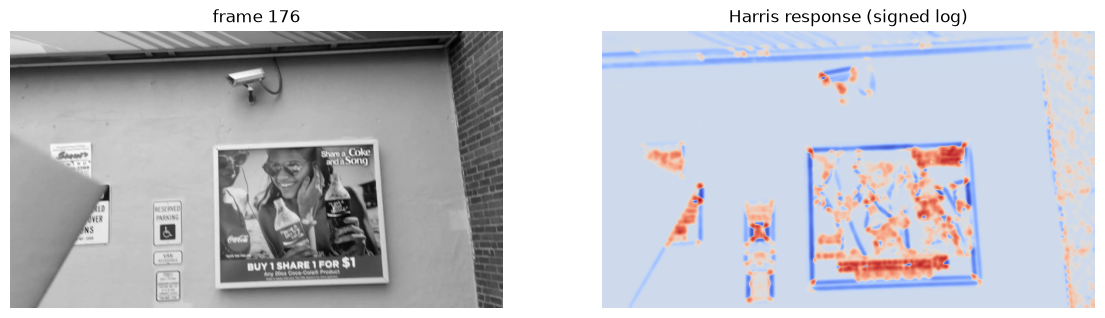

mode      r sigma_w  total  board background
window    4     1.5    243    149         94
window    4     2.0    210    120         90
window    4     3.0    161     89         72
radius    5     1.5    508    342        166
radius    5     2.0    600    412        188
radius    5     3.0    600    434        166
radius    9     1.5    260    161         99
radius    9     2.0    290    176        114
radius    9     3.0    333    208        125


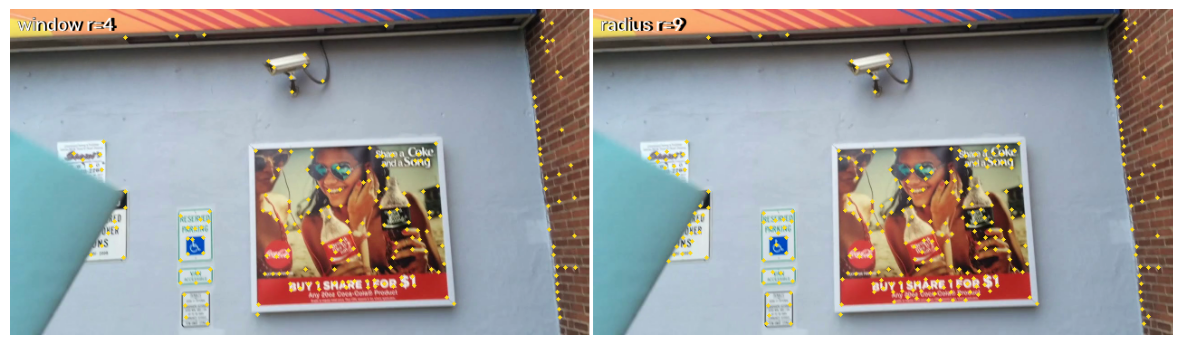

In [3]:
frame_id = next(i for i in indices if i in gt_val and i >= 150)
frame = frames[indices.index(frame_id)]; gray = sp.to_gray(frame)
R = harris_response(gray, config.localisation.detector)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title(f"frame {frame_id}"); axes[0].axis("off")
axes[1].imshow(np.sign(R) * np.log1p(np.abs(R) / (np.abs(R).max() + 1e-9) * 1e3), cmap="coolwarm"); axes[1].set_title("Harris response (signed log)"); axes[1].axis("off")
plt.show()

board = sp.quad_mask(gray.shape, gt_val[frame_id])
rows = []
for mode, radius in [("window", 4), ("radius", 5), ("radius", 9)]:
    for sigma_w in (1.5, 2.0, 3.0):
        det = replace(config.localisation.detector, nms_mode=mode, nms_radius=radius, sigma_w=sigma_w)
        kps, resp = detect_corners(gray, det)
        on_board = board[kps[:, 1].astype(int), kps[:, 0].astype(int)].sum()
        rows.append((mode, radius, sigma_w, len(kps), int(on_board), len(kps) - int(on_board)))
print(f"{'mode':8s} {'r':>2s} {'sigma_w':>7s} {'total':>6s} {'board':>6s} {'background':>10s}")
for r in rows: print(f"{r[0]:8s} {r[1]:2d} {r[2]:7.1f} {r[3]:6d} {r[4]:6d} {r[5]:10d}")
kw, _ = detect_corners(gray, replace(config.localisation.detector, nms_mode="window", nms_radius=4))
kr, _ = detect_corners(gray, replace(config.localisation.detector, nms_mode="radius", nms_radius=9))
plt.figure(figsize=(15, 4.5)); plt.imshow(viz.montage([viz.label(viz.draw_points(frame, kw, radius=2), "window r=4"), viz.label(viz.draw_points(frame, kr, radius=2), "radius r=9")], cols=2)); plt.axis("off"); plt.show()

### EXPLORATION — parameter sweep: window scale, sensitivity constant $\kappa$, NMS mode
Not a report question. Sweep `sigma_w`, `kappa` and the NMS mode and measure two things on a pair of annotated frames:
how many corners land on the board, and how *repeatable* they are (fraction of corners on frame A whose ground-truth
transfer lands within 3 px of a corner on frame B). Decide which setting you keep and why; the choice is yours and goes
into `config.localisation.detector` for the rest of the lab.

In [4]:
fa, fb = sorted(gt_val)[0], sorted(gt_val)[1]
A_, B_ = frames[indices.index(fa)], frames[indices.index(fb)]
H_ab = syn.homography_from_corners(gt_val[fa], gt_val[fb])          # board plane: frame a -> frame b (ground truth, used only to score)

def repeatability(det_cfg, tol=3.0):
    ka, _ = detect_corners(sp.to_gray(A_), det_cfg); kb, _ = detect_corners(sp.to_gray(B_), det_cfg)
    on_a = sp.quad_mask(A_.shape[:2], gt_val[fa])[ka[:, 1].astype(int), ka[:, 0].astype(int)]
    if on_a.sum() == 0 or len(kb) == 0: return 0.0, int(on_a.sum())
    proj = transfer_points(H_ab, ka[on_a])
    d = np.linalg.norm(proj[:, None, :] - kb[None, :, :], axis=2).min(axis=1)
    return float((d < tol).mean()), int(on_a.sum())

print(f"{'mode':8s} {'sigma_w':>7s} {'kappa':>6s} {'on board':>8s} {'repeat.':>8s}")
for mode in ("window", "radius"):
    for sigma_w in (1.5, 2.0, 3.0):
        for kappa in (0.04, 0.06, 0.10):
            r, n = repeatability(replace(config.localisation.detector, nms_mode=mode, sigma_w=sigma_w, kappa=kappa))
            print(f"{mode:8s} {sigma_w:7.1f} {kappa:6.2f} {n:8d} {r:8.2f}")
# YOUR CODE HERE (optional) — plot repeatability against sigma_w for both NMS modes; pick the setting you keep
# Radius NMS has the highest repeatability (0.86) at sigma_w=1.5, kappa=0.04, so we will be using that setting from this cell onwards.
config.localisation.detector = replace(
    config.localisation.detector,
    nms_mode="radius",
    nms_radius=5,
    sigma_w=1.5,
    kappa=0.04,
)

mode     sigma_w  kappa on board  repeat.
window       1.5   0.04      116     0.72
window       1.5   0.06      114     0.74
window       1.5   0.10      114     0.73
window       2.0   0.04      101     0.78
window       2.0   0.06      101     0.80
window       2.0   0.10      103     0.72
window       3.0   0.04       78     0.79
window       3.0   0.06       82     0.84
window       3.0   0.10       78     0.82
radius       1.5   0.04      339     0.86
radius       1.5   0.06      325     0.86
radius       1.5   0.10      296     0.83
radius       2.0   0.04      376     0.83
radius       2.0   0.06      365     0.85
radius       2.0   0.10      346     0.85
radius       3.0   0.04      419     0.83
radius       3.0   0.06      410     0.84
radius       3.0   0.10      392     0.85


## 4. Descriptors and the ratio test
Match the reference to the frame and look at the distribution of first-to-second-neighbour ratios. Repeated texture and
letters produce near-identical neighbours: find one match that the ratio test correctly rejects and one
geometrically correct match that it rejects anyway (material for **Question 1**, Matching).

280 reference and 525 frame descriptors; 280 nearest neighbours, 127 survive the ratio test at 0.8


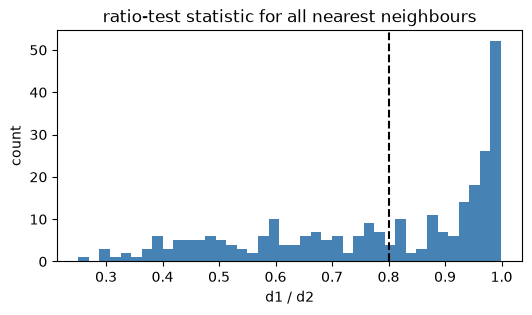

correct nearest neighbours: 170  accepted: 127  correct&accepted: 127  correct&rejected: 43  wrong&accepted: 0


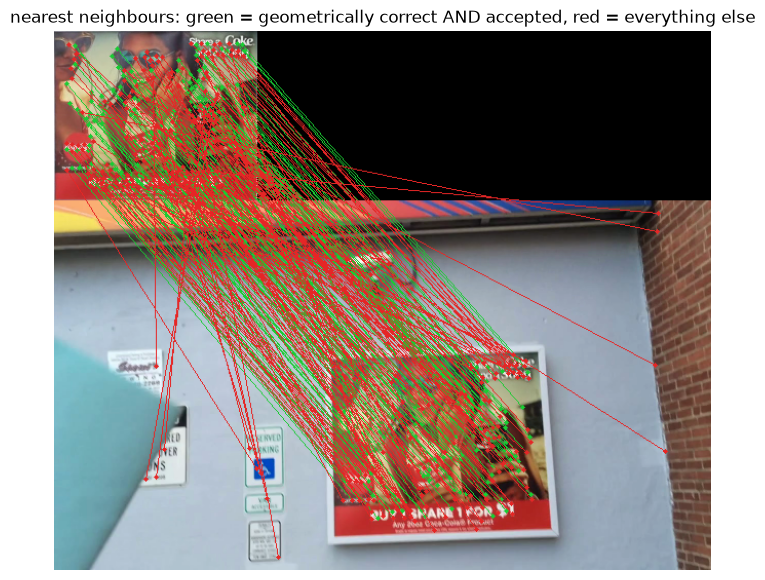

In [5]:
g_ref = sp.to_gray(reference)
kp_r, _ = detect_corners(g_ref, config.localisation.detector); kp_f, _ = detect_corners(gray, config.localisation.detector)
d_r, keep_r = describe_keypoints(g_ref, kp_r, config.localisation.descriptor); kp_r = kp_r[keep_r]
d_f, keep_f = describe_keypoints(gray, kp_f, config.localisation.descriptor); kp_f = kp_f[keep_f]
loose = replace(config.localisation.matcher, ratio=1.01)
pairs_all, dist_all, ratio_all = match_descriptors(d_r, d_f, loose)
pairs, dist, ratio = match_descriptors(d_r, d_f, config.localisation.matcher)
print(f"{len(d_r)} reference and {len(d_f)} frame descriptors; {len(pairs_all)} nearest neighbours, {len(pairs)} survive the ratio test at {config.localisation.matcher.ratio}")
plt.figure(figsize=(6, 3)); plt.hist(ratio_all, bins=40, color="steelblue"); plt.axvline(config.localisation.matcher.ratio, color="k", ls="--")
plt.xlabel("d1 / d2"); plt.ylabel("count"); plt.title("ratio-test statistic for all nearest neighbours"); plt.show()
# geometric truth for the shown frame lets us label every nearest neighbour as correct or not
H_gt = syn.homography_from_corners(sp.rect_corners(reference.shape[1], reference.shape[0]), gt_val[frame_id])
proj = transfer_points(H_gt, kp_r[pairs_all[:, 0]]); err = np.linalg.norm(proj - kp_f[pairs_all[:, 1]], axis=1)
correct = err < 4.0; accepted = ratio_all < config.localisation.matcher.ratio
print(f"correct nearest neighbours: {correct.sum()}  accepted: {accepted.sum()}  correct&accepted: {(correct&accepted).sum()}  correct&rejected: {(correct&~accepted).sum()}  wrong&accepted: {(~correct&accepted).sum()}")
plt.figure(figsize=(12, 7)); plt.imshow(viz.draw_matches(reference, frame, kp_r, kp_f, pairs_all, correct & accepted)); plt.axis("off")
plt.title("nearest neighbours: green = geometrically correct AND accepted, red = everything else"); plt.show()

## 5. Where does matching break? Rotation versus scale and viewpoint
Plot the matching rate against the subset frames. The dominant-orientation normalisation absorbs in-plane rotation;
scale and out-of-plane tilt are not absorbed. **Question 1** asks the same analysis on the two Stage 1 stress clips
(`data.stress_clips(1)`: the **viewpoint** clip, where the camera orbits the poster, and the **scale** clip, where it
approaches and retreats): pick a frame pair on which the rate collapses, separate the in-plane rotation the dominant
orientation absorbs from the viewpoint / scale change it does not, and compare with the labelled SIFT cell below.
Rehearse the analysis here on the common clip first.

Stage 1 choices saved before stress analysis. Do not retune from the stress rows.


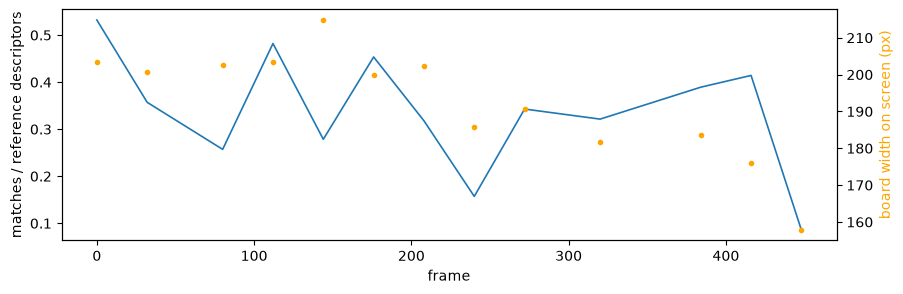

matching rate: original 0.454, rotated 30 deg 0.439, downscaled x0.6 0.036


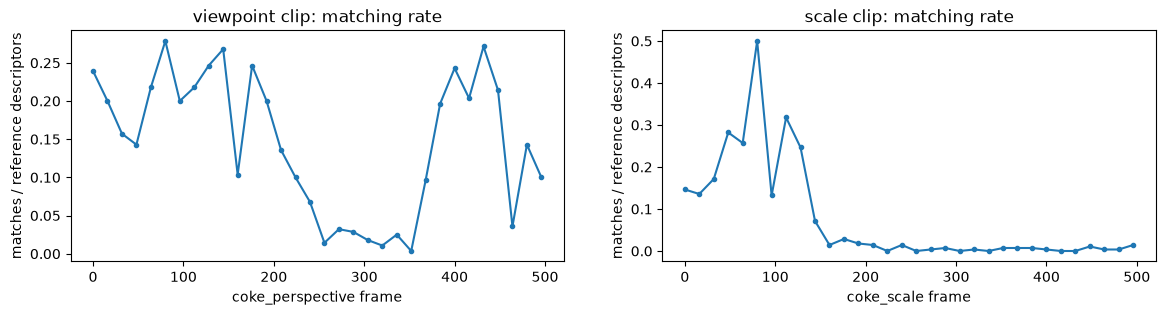

viewpoint (coke_perspective): frames 448 -> 464, match rate 0.214 -> 0.036 (drop 0.179)
  rotation change=-13.5 deg; apparent scale=235.7 -> 222.6; keystone=0.013 -> 0.034
scale (coke_scale): frames 80 -> 96, match rate 0.500 -> 0.132 (drop 0.368)
  rotation change=-1.9 deg; apparent scale=190.5 -> 172.6; keystone=0.014 -> 0.003


In [6]:
def matching_rate(fr):
    g = sp.to_gray(fr); k, _ = detect_corners(g, config.localisation.detector)
    d, keep = describe_keypoints(g, k, config.localisation.descriptor)
    p, _, _ = match_descriptors(d_r, d, config.localisation.matcher)
    return len(p) / max(len(d_r), 1), len(p)
# Development plots use validation frames only.
rate_indices = sorted(gt_val)
rates = [matching_rate(frames[indices.index(i)])[0] for i in rate_indices]
import json
(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "stage1_settings.json").write_text(json.dumps(config.thresholds(), indent=2))
print("Stage 1 choices saved before stress analysis. Do not retune from the stress rows.")
widths = {i: np.linalg.norm(c[1] - c[0]) for i, c in gt_val.items()}
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(rate_indices, rates, lw=1.2); ax.set_xlabel("frame"); ax.set_ylabel("matches / reference descriptors")
ax2 = ax.twinx(); ax2.plot(list(widths), list(widths.values()), "o", color="orange", ms=3); ax2.set_ylabel("board width on screen (px)", color="orange"); plt.show()
# in-plane rotation test: rotate one frame by 30 degrees and match again
M = cv2.getRotationMatrix2D((gray.shape[1] / 2, gray.shape[0] / 2), 30, 1.0)
rot = cv2.warpAffine(frame, M, (gray.shape[1], gray.shape[0]))
print("matching rate: original %.3f, rotated 30 deg %.3f, downscaled x0.6 %.3f" % (
    matching_rate(frame)[0], matching_rate(rot)[0], matching_rate(cv2.resize(frame, None, fx=0.6, fy=0.6))[0]))
# Stage 1 stress clips (Question 1): matching rate on the annotated frames, same reference, same settings
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
for ax, (factor_name, cid) in zip(axes, data.stress_clips(1).items()):
    video_s, _ = data.clip_paths(cid); gt_s = data.load_diagnostic_corners(cid, scale=factor)
    rates_s = {i: matching_rate(fr)[0] for i, fr in sp.iter_video(video_s, step=data.GT_STRIDE, width=frames[0].shape[1]) if i in gt_s}
    ax.plot(list(rates_s), list(rates_s.values()), "o-", ms=3); ax.set_xlabel(f"{cid} frame"); ax.set_ylabel("matches / reference descriptors"); ax.set_title(f"{factor_name} clip: matching rate")
plt.show()
# YOUR CODE HERE — pick the frame pair where the rate collapses and relate it to the in-plane rotation, scale and keystone of the GT quad
def quad_stats(q):
    top = np.linalg.norm(q[1] - q[0])
    bottom = np.linalg.norm(q[2] - q[3])
    theta = np.degrees(np.arctan2(
        q[1, 1] - q[0, 1],
        q[1, 0] - q[0, 0],
    ))
    area = 0.5 * abs(np.sum(
        q[:, 0] * np.roll(q[:, 1], -1)
        - q[:, 1] * np.roll(q[:, 0], -1)
    ))
    keystone = abs(top - bottom) / max((top + bottom) / 2, 1e-9)
    return theta, np.sqrt(area), keystone

for factor_name, cid in data.stress_clips(1).items():
    video_s, _ = data.clip_paths(cid)
    gt_s = data.load_diagnostic_corners(cid, scale=factor)

    samples = []
    for i, fr in sp.iter_video(
        video_s, step=data.GT_STRIDE, width=frames[0].shape[1]
    ):
        if i in gt_s:
            rate, _ = matching_rate(fr)
            samples.append((i, rate, gt_s[i]))

    samples.sort(key=lambda row: row[0])
    pairs = list(zip(samples, samples[1:]))
    (drop, a, b) = max(
        ((ra - rb, left, right)
         for left, right in pairs
         for ra, rb in [(left[1], right[1])]),
        key=lambda item: item[0],
    )

    theta_a, scale_a, key_a = quad_stats(a[2])
    theta_b, scale_b, key_b = quad_stats(b[2])
    delta_theta = (theta_b - theta_a + 180) % 360 - 180

    print(
        f"{factor_name} ({cid}): frames {a[0]} -> {b[0]}, "
        f"match rate {a[1]:.3f} -> {b[1]:.3f} "
        f"(drop {drop:.3f})"
    )
    print(
        f"  rotation change={delta_theta:+.1f} deg; "
        f"apparent scale={scale_a:.1f} -> {scale_b:.1f}; "
        f"keystone={key_a:.3f} -> {key_b:.3f}"
    )

### ABLATION CELL — `cv2.SIFT` baseline (the only cell where SIFT is permitted)
Compare your descriptor's matching rate with SIFT on the same frame pair. Explain the difference in the report.

In [7]:
sift = cv2.SIFT_create()
def sift_rate(a, b):
    ka, da = sift.detectAndCompute(sp.to_uint8(sp.to_gray(a)), None); kb, db = sift.detectAndCompute(sp.to_uint8(sp.to_gray(b)), None)
    if da is None or db is None or len(db) < 2: return 0.0
    good = [pair[0] for pair in cv2.BFMatcher().knnMatch(da, db, k=2) if len(pair) == 2 and pair[0].distance < 0.8 * pair[1].distance]
    return len(good) / max(len(ka), 1)
worst = rate_indices[int(np.argmin(rates))]
print(f"worst subset frame for your descriptor: {worst} (rate {min(rates):.3f});  SIFT rate on the same pair: {sift_rate(reference, frames[indices.index(worst)]):.3f}")

worst subset frame for your descriptor: 448 (rate 0.086);  SIFT rate on the same pair: 0.179


## 6. Normalised DLT and conditioning (EXPLORATION)
Build the same system with and without normalisation and compare the singular values of $A$ and the corner-transfer
error. Then construct a degenerate configuration. This is an exploration, not a report question.

normalised     corner error 0.0472%   condition number sigma_1/sigma_8 = 3.36
un-normalised  corner error 0.0446%   condition number sigma_1/sigma_8 = 2.01e+05
With float64 SVD both solve this small, noise-free-ish system; the conditioning gap is what grows with coordinate magnitude, noise and outliers.


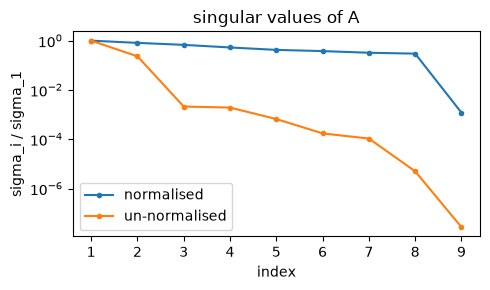

small-patch configuration: status True | corner error 1.7%
collinear configuration: status False


In [8]:
H_true, dst_corners = syn.random_homography(seed=1, frame_size=(640, 360), board_size=(reference.shape[1], reference.shape[0]))
src, dst, _ = syn.synthetic_correspondences(H_true, n_inliers=40, noise=0.3, seed=2,
                                            src_range=(0, reference.shape[1], 0, reference.shape[0]), dst_shape=(360, 640))
H_norm, s_norm, ok = dlt_homography(src, dst)
# the un-normalised system, built here only for the comparison
A = np.zeros((2 * len(src), 9)); x, y = src[:, 0], src[:, 1]; xp, yp = dst[:, 0], dst[:, 1]
A[0::2, 0] = -x; A[0::2, 1] = -y; A[0::2, 2] = -1; A[0::2, 6] = xp * x; A[0::2, 7] = xp * y; A[0::2, 8] = xp
A[1::2, 3] = -x; A[1::2, 4] = -y; A[1::2, 5] = -1; A[1::2, 6] = yp * x; A[1::2, 7] = yp * y; A[1::2, 8] = yp
_, s_raw, vt = np.linalg.svd(A); H_raw = vt[-1].reshape(3, 3); H_raw /= H_raw[2, 2]
ref_c = sp.rect_corners(reference.shape[1], reference.shape[0])
for name, H, sv in [("normalised", H_norm, s_norm), ("un-normalised", H_raw, s_raw)]:
    print(f"{name:14s} corner error {metrics.corner_error(transfer_points(H, ref_c), dst_corners) * 100:.4f}%   "
          f"condition number sigma_1/sigma_8 = {sv[0] / sv[7]:.3g}")
print("With float64 SVD both solve this small, noise-free-ish system; the conditioning gap is what grows with coordinate magnitude, noise and outliers.")
viz.plot_singular_values([s_norm, s_raw], ["normalised", "un-normalised"], "singular values of A"); plt.show()
# degenerate: all correspondences inside a small patch of the board
patch_src, patch_dst, _ = syn.synthetic_correspondences(H_true, n_inliers=30, noise=0.3, seed=3, src_range=(600, 680, 150, 180))
H_patch, s_patch, ok_patch = dlt_homography(patch_src, patch_dst)
print("small-patch configuration: status", ok_patch, "| corner error %.1f%%" % (metrics.corner_error(transfer_points(H_patch, ref_c), dst_corners) * 100 if H_patch is not None else float("nan")))
coll = np.stack([np.linspace(0, 400, 6), np.linspace(0, 100, 6)], 1); print("collinear configuration: status", dlt_homography(coll, coll * 2)[2])

### EXPLORATION — when does normalisation matter, and what does a degenerate configuration look like?
Scaffold: shift the correspondences to large coordinates (e.g. add 4000 px, as in a 4K frame) and add noise, and watch the
condition number and the corner error of the un-normalised system diverge from the normalised one. Then make three of the
four points collinear plus one more and inspect the singular values: the second-smallest one tells you that the solution
is not unique.

In [9]:
def raw_dlt(src, dst):
    A = np.zeros((2 * len(src), 9)); x, y = src[:, 0], src[:, 1]; xp, yp = dst[:, 0], dst[:, 1]
    A[0::2, 0] = -x; A[0::2, 1] = -y; A[0::2, 2] = -1; A[0::2, 6] = xp * x; A[0::2, 7] = xp * y; A[0::2, 8] = xp
    A[1::2, 3] = -x; A[1::2, 4] = -y; A[1::2, 5] = -1; A[1::2, 6] = yp * x; A[1::2, 7] = yp * y; A[1::2, 8] = yp
    _, sv, vt = np.linalg.svd(A); H = vt[-1].reshape(3, 3); return H / H[2, 2], sv

print(f"{'offset':>7s} {'noise':>6s} {'cond (norm)':>12s} {'cond (raw)':>11s} {'err norm':>9s} {'err raw':>8s}")
for offset in (0.0, 2000.0, 8000.0):
    for noise in (0.3, 2.0):
        s2, d2, _ = syn.synthetic_correspondences(H_true, n_inliers=12, noise=noise, seed=5, src_range=(0, reference.shape[1], 0, reference.shape[0]), dst_shape=(360, 640))
        Hn, svn, _ = dlt_homography(s2 + offset, d2 + offset); Hr, svr = raw_dlt(s2 + offset, d2 + offset)
        en = metrics.corner_error(transfer_points(Hn, ref_c + offset) - offset, dst_corners) * 100
        er = metrics.corner_error(transfer_points(Hr, ref_c + offset) - offset, dst_corners) * 100
        print(f"{offset:7.0f} {noise:6.1f} {svn[0]/svn[7]:12.3g} {svr[0]/svr[7]:11.3g} {en:8.3f}% {er:7.3f}%")
# degenerate: three collinear points + one more (a 4-point minimal set with no unique solution)
deg_src = np.array([[0, 0], [100, 0], [200, 0], [50, 80]], float); deg_dst = transfer_points(H_true, deg_src)
Hd, sd, okd = dlt_homography(deg_src, deg_dst)
print("3 collinear + 1: status", okd, "| two smallest singular values", sd[-2:], "(both ~0 => the null space is 2-dimensional)")
# YOUR CODE HERE (optional) — plot the full singular-value spectra of the degenerate and the generic 4-point systems

 offset  noise  cond (norm)  cond (raw)  err norm  err raw
      0    0.3          4.2    1.65e+05    0.091%   0.090%
      0    2.0         4.19    1.66e+05    0.602%   0.588%
   2000    0.3          4.2    6.88e+08    0.091%   0.087%
   2000    2.0         4.19    7.89e+08    0.602%   0.542%
   8000    0.3          4.2    2.84e+10    0.091%   0.088%
   8000    2.0         4.19    3.21e+10    0.602%   0.524%
3 collinear + 1: status False | two smallest singular values [9.69565313e-01 3.02167157e-16] (both ~0 => the null space is 2-dimensional)


### SANITY-CHECK CELL — `cv2.findHomography` (the only cell where it is permitted)

In [10]:
H_cv, _ = cv2.findHomography(src.astype(np.float32), dst.astype(np.float32), 0)
print("max |H_ours - H_cv| after normalising H[2,2]:", np.abs(H_norm / H_norm[2, 2] - H_cv / H_cv[2, 2]).max())

max |H_ours - H_cv| after normalising H[2,2]: 0.0010788385274054235


## 7. RANSAC: inlier threshold, iterations, and $N(p,\varepsilon)$ (EXPLORATION)
Vary the threshold and the iteration cap on correspondences with injected outliers, and relate the inlier count and the
corner error to the required iteration count. The residual histogram is the evidence you should show for any failure
case in the report; the sweep itself is an exploration, not a report question.

  thr max_it  used inliers corner err
  2.0     20    20       4       nan%
  2.0    200   200      43     0.267%
  2.0   2000   221      54     0.066%
  4.0     20    20       4       nan%
  4.0    200   200      55     0.226%
  4.0   2000   219      59     0.065%
  9.0     20    20       4       nan%
  9.0    200   160      60     0.113%
  9.0   2000   160      60     0.113%
 25.0     20    20       5       nan%
 25.0    200    88      60     0.051%
 25.0   2000    88      60     0.051%


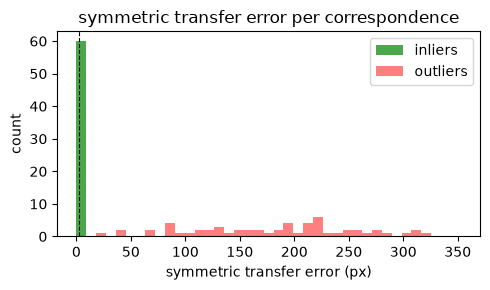

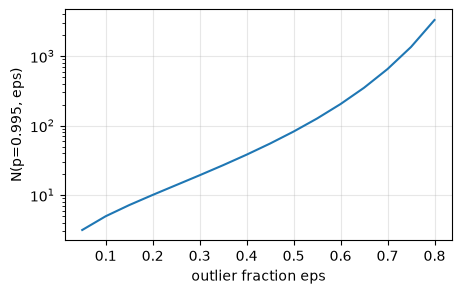

In [11]:
src_o, dst_o, is_in = syn.synthetic_correspondences(H_true, n_inliers=60, n_outliers=60, noise=0.5, seed=4,
                                                   src_range=(0, reference.shape[1], 0, reference.shape[0]), dst_shape=(360, 640))
print(f"{'thr':>5s} {'max_it':>6s} {'used':>5s} {'inliers':>7s} {'corner err':>10s}")
for thr in (2.0, 4.0, 9.0, 25.0):
    for max_it in (20, 200, 2000):
        H, inl, resid, used, ok = ransac_homography(src_o, dst_o, replace(config.localisation.ransac, threshold=thr, max_iterations=max_it, seed=0))
        e = metrics.corner_error(transfer_points(H, ref_c), dst_corners) * 100 if H is not None else float("nan")
        print(f"{thr:5.1f} {max_it:6d} {used:5d} {int(inl.sum()):7d} {e:9.3f}%")
H, inl, resid, used, ok = ransac_homography(src_o, dst_o, config.localisation.ransac)
viz.plot_residual_histogram(resid, inl, config.localisation.ransac.threshold, "symmetric transfer error per correspondence"); plt.show()
eps = np.linspace(0.05, 0.8, 16); N = np.log(1 - 0.995) / np.log(1 - (1 - eps) ** 4)
plt.figure(figsize=(5, 3)); plt.semilogy(eps, N); plt.xlabel("outlier fraction eps"); plt.ylabel("N(p=0.995, eps)"); plt.grid(alpha=.3); plt.show()

### EXPLORATION — does the adaptive iteration count match $N(p,\varepsilon)$?
Scaffold: for several true outlier fractions, run RANSAC with a large iteration cap and compare the number of iterations it
*used* with $N(p,\varepsilon)$ computed from the inlier fraction it *found*; then check how often the result is a success
over repeated seeds when the cap is below $N$.

In [13]:
def N_required(p, eps, s=4):
    return int(np.ceil(np.log(1 - p) / np.log(1 - (1 - eps) ** s)))

print(f"{'true eps':>8s} {'found eps':>9s} {'N(0.995)':>8s} {'used':>5s} {'success@cap=N/4':>15s}")
for n_out in (20, 60, 120, 180):
    s3, d3, in3 = syn.synthetic_correspondences(H_true, n_inliers=60, n_outliers=n_out, noise=0.5, seed=7, src_range=(0, reference.shape[1], 0, reference.shape[0]), dst_shape=(360, 640))
    H, inl, resid, used, ok = ransac_homography(s3, d3, replace(config.localisation.ransac, max_iterations=5000, seed=0))
    eps_found = 1 - inl.mean(); N = N_required(0.995, eps_found)
    succ = []
    for seed in range(10):
        Hs, *_ = ransac_homography(s3, d3, replace(config.localisation.ransac, max_iterations=max(1, N // 4), seed=seed))
        succ.append(Hs is not None and metrics.corner_error(transfer_points(Hs, ref_c), dst_corners) < 0.01)
    print(f"{n_out/(60+n_out):8.2f} {eps_found:9.2f} {N:8d} {used:5d} {np.mean(succ):15.0%}")
# YOUR CODE HERE (optional) — repeat with threshold 2 / 9 / 25 px and explain why the found inlier fraction moves with the threshold

true eps found eps N(0.995)  used success@cap=N/4
    0.25      0.25       14    17             40%
    0.50      0.50       83    83             60%
    0.67      0.67      427   427             40%
    0.75      0.75     1354  1551             70%


## 8. Warping convention check
A synthetic checkerboard warped with a known homography must land on the expected corners. State in your report whether
`x` indexes columns and where your pixel centres sit.

coverage bbox x: 60 300  y: 40 150 | expected approx 60.0 300.0 40.0 150.0


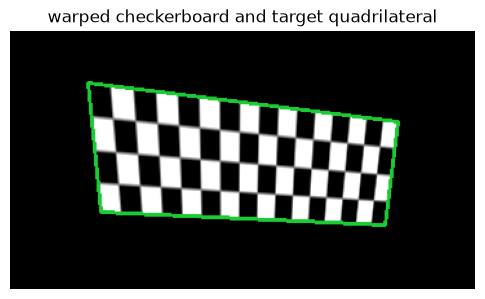

In [14]:
cb = np.repeat(syn.checkerboard(4, 16, 8)[..., None], 3, -1)   # 32 x 128 artwork
target = np.array([[60, 40], [300, 70], [290, 150], [70, 140]], float)
H_cb = syn.homography_from_corners(sp.rect_corners(128, 32), target)
warped, cov = warp_artwork(cb, H_cb, (200, 360, 3))
ys, xs = np.nonzero(cov)
print("coverage bbox x:", xs.min(), xs.max(), " y:", ys.min(), ys.max(), "| expected approx", target[:, 0].min(), target[:, 0].max(), target[:, 1].min(), target[:, 1].max())
plt.figure(figsize=(6, 3.5)); plt.imshow(viz.draw_quad(warped, target)); plt.axis("off"); plt.title("warped checkerboard and target quadrilateral"); plt.show()

### COMPARISON CELL — `cv2.warpPerspective` (the only cell where it is permitted)

In [15]:
ref_cv = cv2.warpPerspective(cb, H_cb.astype(np.float32), (360, 200))
print("mean |ours - cv2| inside coverage:", float(np.abs(warped - ref_cv)[cov].mean()))

mean |ours - cv2| inside coverage: 6.148228521851706e-07


## Reflection prompts
1. Which NMS mode gives better spatial coverage of the board, and at what cost in repeatability?

- Radius NMS gave substantially more on-board corners than window NMS. In the sweep, the strongest radius results had 325–339 on-board corners and 0.86 repeatability; the best window result had 82 corners and 0.84 repeatability. So this run shows no repeatability cost for radius NMS, though its greedy suppression can remove nearby corners. The selected result was radius, sigma_w=1.5, kappa=0.04.

2. On which frames does the ratio test discard most of the correct matches, and why?

- On the common-clip validation frame 176, the ratio test rejected 43 of 170 geometrically correct nearest-neighbour matches, which is about 25%. It accepted 127 correct matches and no incorrect ones in this example. Repeated poster textures can give a correct match a similarly close second neighbour, so its ratio is ambiguous and the test rejects it.

3. What does the second-smallest singular value of $A$ tell you that the smallest does not?

- The smallest singular value corresponds to the best-fit homography direction and is expected to be near zero for consistent correspondences. The second-smallest value indicates the uniqueness of that solution. If it is also near zero, the system has another near-null direction and the homography is underconstrained or degenerate.

4. On the viewpoint and scale clips, which part of the change does your descriptor survive, and which part does SIFT survive that yours does not (**Question 1**)?

- The descriptor handled in-plane rotation fairly well. The common-frame match rate changed from 0.454 to 0.439 after a 30º rotation. It was less robust to scale as downscaling by 0.6 reduced the rate to 0.036. 
In the scale stress clip, the rate dropped from 0.500 to 0.132 between frames 80 and 96 while rotation and keystone changed little. In the viewpoint clip, it dropped from 0.214 to 0.036 between frames 448 and 464 as keystone increased from 0.013 to 0.034. This descriptor normalises orientation but uses a fixed patch scale and does not remove perspective distortion. SIFT’s scale-space detection should handle scale changes better. The saved SIFT comparison was on a common-clip frame, where SIFT scored 0.179 versus 0.086 for this descriptor. It was not run on those exact stress-frame pairs, so that comparison doesn’t quantify the stress-clip difference.